# EV Infra Map India — Phase 3: EDA, forecast and charger need (Odisha, Karnataka benchmark)
Techfest IIT Bombay 2026-27 · Challenge 1 · Team TM-72BD3802D52

Private evidence notebook (not submitted). Scope and parameters come from `Phase1_Scope.md` and `Phase2_DataResearch.md`.
Anything synthetic or assumed carries an `is_assumed` / `is_synthetic` flag and is listed in `outputs/tables/data_quality_log.md`.

## 0. Setup and planning parameters

In [1]:
import json, glob, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, h3, rasterio
from rasterio.mask import mask
from shapely.geometry import LineString, Point
from shapely.ops import polygonize, unary_union
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW, PROC = ROOT/'data/raw', ROOT/'data/processed'
FIG, TAB = ROOT/'outputs/figures', ROOT/'outputs/tables'
UTM = 32645                      # WGS84 / UTM 45N (Odisha); used only for distances/areas
LOG = []
def log(section, item, value, note=''):
    LOG.append(dict(section=section, item=item, value=value, note=note))

In [2]:
SEG = ['2W', '3W_AUTO', '3W_ERICK', '4W']
P = pd.DataFrame({
    'daily_km':     {'2W': 25,   '3W_AUTO': 100,  '3W_ERICK': 70,    '4W': 35},
    'wh_per_km':    {'2W': 33,   '3W_AUTO': 60,   '3W_ERICK': 77,    '4W': 123},
    'public_share': {'2W': 0.10, '3W_AUTO': 0.30, '3W_ERICK': 0.025, '4W': 0.20},
    'attrition':    {'2W': 0.02, '3W_AUTO': 0.02, '3W_ERICK': 0.10,  '4W': 0.0},
    'dc_share':     {'2W': 0.0,  '3W_AUTO': 0.0,  '3W_ERICK': 0.0,   '4W': 0.6},
})
P['source'] = ['Phase2 D (Ather/CSTEP; LBNL; Kazam-AEEE)', 'Phase2 D (WRI; LBNL)', 'Phase2 D (SAE; WRI); share = midpoint of 0-5%', 'Phase2 D (LBNL city); km assumed']
P['is_assumed'] = [False, True, True, True]
CHG = dict(light_kw=7.4, dc_kw=60, light_hours=6, dc_hours=4)   # Phase2 D planning targets
OFFICIAL = {'Odisha': (606, 'MHI state table Dec 2025 via India Data Report (Phase2 C1) - unverified'),
            'Karnataka': (6805, 'MHI Rajya Sabha unstarred reply 7 Aug 2026 (installed as of 29 Jul 2026)')}
for k, v in [('3W_AUTO attrition', '2%/yr (no Phase2 value)'), ('4W DC share of public energy', '60%'),
             ('Representative light charger', '7.4 kW'), ('Representative DC charger', '60 kW')]:
    log('Assumptions', k, v, 'is_assumed')
P

,daily_km,wh_per_km,public_share,attrition,dc_share,source,is_assumed
2W,25,33,0.100,0.02,0.0,Phase2 D (Ather/CSTEP; LBNL; Kazam-AEEE),False
3W_AUTO,100,60,0.300,0.02,0.0,Phase2 D (WRI; LBNL),True
3W_ERICK,70,77,0.025,0.10,0.0,Phase2 D (SAE; WRI); share = midpoint of 0-5%,True
4W,35,123,0.200,0.00,0.6,Phase2 D (LBNL city); km assumed,True


## 1. Data pull
### 1a. District boundaries (OSM admin_level 5, ODbL) and population (WorldPop 2020, 1 km, CC BY 4.0)

In [3]:
def rel_polys(path):
    rows = []
    for e in json.load(open(path, encoding='utf-8'))['elements']:
        lines = [LineString([(p['lon'], p['lat']) for p in m['geometry']])
                 for m in e.get('members', []) if m['type'] == 'way' and m.get('geometry')]
        t = e['tags']
        rows.append(dict(name=t.get('name:en', t.get('name')), admin_level=t.get('admin_level'), osm_id=e['id'],
                         geometry=unary_union(list(polygonize(unary_union(lines))))))
    return gpd.GeoDataFrame(rows, crs=4326)

FIX = {'Mysuru District': 'Mysuru', 'Coorg': 'Kodagu', 'Shimoga': 'Shivamogga'}
dist = pd.concat([rel_polys(RAW/'osm_districts_IN-OD.json').assign(state='Odisha'),
                  rel_polys(RAW/'osm_districts_IN-KA.json').assign(state='Karnataka')], ignore_index=True)
dist['district'] = dist['name'].replace(FIX)
for a, b in FIX.items(): log('Boundaries', f'name fix {a}', b, 'OSM name -> common/LGD name')
dist['area_km2'] = dist.to_crs(6933).area / 1e6          # equal-area CRS
with rasterio.open(RAW/'ind_ppp_2020_1km_Aggregated_UNadj.tif') as src:
    pops = []
    for g in dist.geometry:
        a, _ = mask(src, [g], crop=True, nodata=0); pops.append(float(a[0][a[0] > 0].sum()))
dist['pop_2020'] = pops
dist = dist[['state', 'district', 'osm_id', 'area_km2', 'pop_2020', 'geometry']]
n = dist.state.value_counts()
assert n['Odisha'] == 30 and n['Karnataka'] == 31, n
for s in ['Odisha', 'Karnataka']:
    d = dist[dist.state == s]
    log('Boundaries', f'{s} districts', len(d), f'area {d.area_km2.sum():,.0f} km2; WorldPop-2020 pop {d.pop_2020.sum()/1e6:.1f} M')
dist.to_file(PROC/'districts_od_ka.geojson', driver='GeoJSON')
dist.drop(columns='geometry').groupby('state')[['area_km2', 'pop_2020']].sum()

,area_km2,pop_2020
state,,
Karnataka,191829.935974,6.891191e+07
Odisha,155508.751754,4.645062e+07


### 1b. EV registrations — VAHAN 4 dashboard (MoRTH), fuel = ELECTRIC(BOV) + PURE EV, read RTO × vehicle class × FY

In [4]:
v = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(RAW/'vahan/vahan_odisha_rto_segment_fy*.csv')))]).drop_duplicates()
tot = v[v.segment == 'TOTAL'].groupby('fy_start').registrations.sum()
segsum = v[v.segment != 'TOTAL'].groupby('fy_start').registrations.sum()
assert (tot == segsum).all()
log('VAHAN', 'Odisha FYs covered', f'FY{tot.index.min()}-{str(tot.index.min()+1)[2:]} to FY{tot.index.max()}-{str(tot.index.max()+1)[2:]}', 'segment sums = TOTAL column for every FY')
log('VAHAN', 'Odisha RTO offices with EV records', v.rto.nunique(), 'of 39 offices in VAHAN dropdown (STA OD99 had none)')

xw = pd.read_csv(PROC/'rto_district_crosswalk_odisha.csv')
v = v[v.segment != 'TOTAL'].merge(xw[['rto_name', 'rto_code', 'district', 'is_assumed']], left_on='rto', right_on='rto_name', how='left')
assert v.district.notna().all(), v[v.district.isna()].rto.unique()
sta = v[v.district == 'ALL']
if len(sta):
    share = v[v.district != 'ALL'].groupby(['fy_start', 'segment', 'district']).registrations.sum()
    share = share / share.groupby(level=[0, 1]).transform('sum')
    alloc = sta.groupby(['fy_start', 'segment']).registrations.sum().to_frame('n').join(share.rename('w').reset_index().set_index(['fy_start', 'segment']))
    v = pd.concat([v[v.district != 'ALL'], alloc.assign(registrations=lambda d: d.n * d.w).reset_index()[['fy_start', 'segment', 'district', 'registrations']]])
log('VAHAN', 'RTO->district crosswalk', f'{xw.district.ne("ALL").sum()} offices -> {xw.district[xw.district!="ALL"].nunique()} districts', 'official VAHAN office list; Chandikhole flagged is_assumed')
reg_od = v.groupby(['district', 'segment', 'fy_start']).registrations.sum().reset_index()
assert set(reg_od.district) <= set(dist[dist.state == 'Odisha'].district)

ka_path = RAW/'vahan/vahan_karnataka_state_segment_fy.csv'
reg_ka = pd.read_csv(ka_path) if ka_path.exists() else None
log('VAHAN', 'Karnataka', 'state level' if reg_ka is not None else 'MISSING', 'same VAHAN query, aggregated to state')
reg_od.pivot_table(index='fy_start', columns='segment', values='registrations', aggfunc='sum').round(0)

segment,2W,3W_AUTO,3W_ERICK,4W,BUS,OTHER
fy_start,,,,,,
2017,212.0,3.0,183.0,9.0,NaN,76.0
2018,1079.0,16.0,362.0,4.0,NaN,25.0
2019,708.0,19.0,261.0,1.0,NaN,1.0
2020,995.0,38.0,301.0,25.0,NaN,NaN
2021,9357.0,56.0,837.0,139.0,NaN,NaN
2022,29115.0,713.0,1930.0,536.0,35.0,1.0
2023,44538.0,2053.0,3391.0,1797.0,72.0,126.0
2024,56000.0,2305.0,3902.0,2656.0,139.0,252.0
2025,79506.0,3145.0,3756.0,5308.0,203.0,681.0


In [5]:
def stock(reg, year, by):
    r = reg[reg.fy_start <= year].copy()
    r['surv'] = (1 - r.segment.map(P.attrition)) ** (year - r.fy_start)
    r['stock'] = r.registrations * r.surv
    return r.groupby(by).stock.sum()

first = reg_od.fy_start.min()
stock_od = stock(reg_od[reg_od.segment.isin(SEG + ['BUS', 'OTHER'])], 2025, ['district', 'segment']).unstack(fill_value=0)
for s in SEG + ['BUS', 'OTHER']:
    if s not in stock_od: stock_od[s] = 0
stock_od['ev_stock_in_scope'] = stock_od[SEG].sum(axis=1)
log('VAHAN', 'Odisha EV stock end-FY2025-26 (in-scope 2W/3W/4W, net of attrition)', f'{stock_od.ev_stock_in_scope.sum():,.0f}',
    f'cumulative VAHAN registrations from FY{first}-{str(first+1)[2:]}; pre-{first} stock not included')
log('VAHAN', 'Gross registrations (all EV classes) Odisha', f'{reg_od.registrations.sum():,.0f}', 'cross-check: state Economic Survey ~2.19 lakh by early 2025 incl. legacy stock')
stock_od.round(0).sort_values('ev_stock_in_scope', ascending=False).head(10)

segment,2W,3W_AUTO,3W_ERICK,4W,BUS,OTHER,ev_stock_in_scope
district,,,,,,,
Khordha,56112.0,1488.0,1471.0,6415.0,0.0,238.0,65486.0
Cuttack,28226.0,1029.0,315.0,1408.0,100.0,119.0,30978.0
Baleshwar,14225.0,1315.0,2770.0,397.0,0.0,67.0,18707.0
Puri,10170.0,524.0,4594.0,91.0,0.0,4.0,15379.0
Ganjam,13494.0,483.0,456.0,122.0,25.0,8.0,14555.0
Sundargarh,12706.0,215.0,182.0,327.0,0.0,12.0,13430.0
Mayurbhanj,9960.0,457.0,903.0,96.0,0.0,15.0,11417.0
Jajpur,10759.0,114.0,32.0,105.0,20.0,31.0,11010.0
Sambalpur,5552.0,212.0,792.0,553.0,40.0,5.0,7109.0


### 1c. Public chargers — OpenChargeMap export (snapshot 22 Apr 2026) + OpenStreetMap (Overpass, 17 Oct 2026)

In [6]:
ref = json.load(open(RAW/'ocm-export/data/referencedata.json', encoding='utf-8'))
USAGE = {u['ID']: u['Title'] for u in ref['UsageTypes']}
STATUS = {s['ID']: s.get('IsOperational') for s in ref['StatusTypes']}
OPS = {o['ID']: o['Title'] for o in ref['Operators']}
DC_CONN = {32, 33, 2, 1044, 1040}
rows = []
for f in glob.glob(str(RAW/'ocm-export/data/IN/*.json')):
    p = json.load(open(f, encoding='utf-8')); a = p.get('AddressInfo') or {}; con = p.get('Connections') or []
    kws = [c.get('PowerKW') for c in con if c.get('PowerKW')]
    rows.append(dict(source='OCM', src_id=f"OCM-{p['ID']}", name=a.get('Title'), operator=OPS.get(p.get('OperatorID'), ''),
                     lat=a.get('Latitude'), lon=a.get('Longitude'),
                     n_points=p.get('NumberOfPoints') or sum((c.get('Quantity') or 1) for c in con) or np.nan,
                     max_kw=max(kws) if kws else np.nan,
                     has_dc_conn=any(c.get('CurrentTypeID') == 30 or c.get('ConnectionTypeID') in DC_CONN for c in con),
                     access=USAGE.get(p.get('UsageTypeID'), '(Unknown)'), operational=STATUS.get(p.get('StatusTypeID')),
                     is_swap=False, created=p.get('DateCreated')))
ocm = pd.DataFrame(rows)

def kw_from_osm(t):
    vals = [float(m) for k, val in t.items() if k.endswith(':output') or k == 'charging_station:output'
            for m in re.findall(r'([\d.]+)\s*kW', str(val), flags=re.I)]
    return max(vals) if vals else np.nan
rows = []
for iso in ['IN-OD', 'IN-KA']:
    for e in json.load(open(RAW/f'osm_chargers_{iso}.json', encoding='utf-8'))['elements']:
        t = e.get('tags', {}); lat = e.get('lat', e.get('center', {}).get('lat')); lon = e.get('lon', e.get('center', {}).get('lon'))
        cap = pd.to_numeric(t.get('capacity'), errors='coerce')
        rows.append(dict(source='OSM', src_id=f"OSM-{e['type']}-{e['id']}", name=t.get('name'), operator=t.get('operator', t.get('brand', '')),
                         lat=lat, lon=lon, n_points=cap, max_kw=kw_from_osm(t),
                         has_dc_conn=any(k in t for k in ['socket:type2_combo', 'socket:chademo', 'socket:gb_dc']),
                         access=t.get('access', '(Unknown)'), operational=None,
                         is_swap=t.get('amenity') == 'battery_swap' or t.get('charging_station:battery_swapping') == 'yes'
                                 or t.get('battery_swapping') == 'yes', created=None))
osm = pd.DataFrame(rows)
raw = pd.concat([ocm, osm], ignore_index=True)
raw = gpd.GeoDataFrame(raw, geometry=gpd.points_from_xy(raw.lon, raw.lat), crs=4326)
raw = gpd.sjoin(raw, dist[['state', 'district', 'geometry']], predicate='within', how='inner').drop(columns='index_right')
for (s, src), n in raw.groupby(['state', 'source']).size().items():
    log('Chargers', f'raw records {s} {src}', n, 'inside state polygons')
raw.groupby(['state', 'source']).size().unstack()

source,OCM,OSM
state,,
Karnataka,379,67
Odisha,239,2


In [7]:
c = raw.copy()
m_priv = c.access.str.contains('Private|private|^no$|customers', regex=True)
m_dead = c.operational.eq(False)
for s in ['Odisha', 'Karnataka']:
    log('Chargers', f'{s} dropped private/captive', int((m_priv & c.state.eq(s)).sum()), 'OCM usage "Private*"; OSM access=private/customers/no')
    log('Chargers', f'{s} dropped non-operational/planned/removed', int((m_dead & ~m_priv & c.state.eq(s)).sum()), 'OCM StatusType IsOperational=False')
    log('Chargers', f'{s} battery-swap records (separate layer)', int((c.is_swap & c.state.eq(s)).sum()), 'kept out of charge-point counts')
c = c[~m_priv & ~m_dead & ~c.is_swap].copy()

DC_OPS = r'chargezone|jio|indian ?oil|iocl|bpcl|bharat petroleum|hpcl|hindustan petroleum|fortum|zeon|glida|shell'
c['is_kw_imputed'] = c.max_kw.isna()
c['kw_class'] = np.where(c.max_kw >= 30, 'DC', np.where(c.max_kw.notna(), 'light', None))
imp = c.kw_class.isna()
c.loc[imp, 'kw_class'] = np.where(c.loc[imp, 'has_dc_conn'] | c.loc[imp, 'operator'].str.contains(DC_OPS, case=False, regex=True, na=False), 'DC', 'light')
c['is_points_imputed'] = c.n_points.isna() | (c.n_points <= 0)
med_pts = c.loc[~c.is_points_imputed].groupby('kw_class').n_points.median()
c.loc[c.is_points_imputed, 'n_points'] = c.loc[c.is_points_imputed, 'kw_class'].map(med_pts)
for s in ['Odisha', 'Karnataka']:
    d = c[c.state == s]
    log('Chargers', f'{s} kW class imputed', int(d.is_kw_imputed.sum()), 'DC if DC connector or DC-heavy operator, else light')
    log('Chargers', f'{s} points imputed', int(d.is_points_imputed.sum()), f'median points by class: {med_pts.to_dict()}')
    log('Chargers', f'{s} missing coordinates', int(raw[(raw.state == s)].lat.isna().sum()), '')

# de-duplication: same operator <=50 m, or any operator <=15 m with same kW class
c = c.to_crs(UTM).reset_index(drop=True)
c['op_key'] = c.operator.fillna('').str.lower().str.replace(r'[^a-z0-9 ]', '', regex=True).str.split().str[0].fillna('')
parent = list(range(len(c)))
def find(i):
    while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
    return i
pairs = gpd.sjoin_nearest(c[['geometry']], c[['geometry']], max_distance=50, distance_col='d', exclusive=True)
for i, r in pairs.iterrows():
    j = r.index_right
    same_op = c.op_key[i] != '' and c.op_key[i] == c.op_key[j]
    if (r.d <= 50 and same_op) or (r.d <= 15 and c.kw_class[i] == c.kw_class[j]):
        parent[find(i)] = find(j)
c['site_id'] = [find(i) for i in range(len(c))]
c['n_fields'] = c[['operator', 'max_kw', 'n_points', 'name']].notna().sum(axis=1)
c = c.sort_values(['site_id', 'n_fields', 'n_points'], ascending=[True, False, False])
src_ids = c.groupby('site_id').src_id.agg(';'.join)
chg = c.drop_duplicates('site_id').set_index('site_id').assign(source_ids=src_ids).reset_index()
for s in ['Odisha', 'Karnataka']:
    log('Chargers', f'{s} duplicates removed', int((c.state == s).sum() - (chg.state == s).sum()), 'union-find over 15/50 m rules')
chg = chg.to_crs(4326)
chg[['state', 'district', 'source', 'source_ids', 'name', 'operator', 'lat', 'lon', 'n_points', 'max_kw', 'kw_class',
     'is_kw_imputed', 'is_points_imputed', 'access', 'created']].to_csv(PROC/'chargers_merged_od_ka.csv', index=False)
summ = chg.groupby('state').agg(sites=('site_id', 'size'), points=('n_points', 'sum'),
                                dc_sites=('kw_class', lambda s: (s == 'DC').sum()))
summ['official_stations'] = [OFFICIAL[s][0] for s in summ.index]
summ['completeness'] = summ.sites / summ.official_stations
for s, r in summ.iterrows():
    log('Chargers', f'{s} completeness ratio (our sites / official stations)', f'{r.completeness:.0%}', f'{r.sites} vs {r.official_stations} ({OFFICIAL[s][1]})')
summ

,sites,points,dc_sites,official_stations,completeness
state,,,,,
Karnataka,415,627.0,296,6805,0.060985
Odisha,229,280.0,49,606,0.377888


## 2. Data quality log (written to `outputs/tables/data_quality_log.md` at the end)

## 3. EDA
### 3a. EV stock and growth by segment

In [8]:
seg_fy = reg_od[reg_od.segment.isin(SEG)].pivot_table(index='fy_start', columns='segment', values='registrations', aggfunc='sum').fillna(0)
seg_fy.index = [f'FY{y}-{str(y+1)[2:]}' for y in seg_fy.index]
cagr = (seg_fy.iloc[-1] / seg_fy.iloc[0].replace(0, np.nan)) ** (1 / (len(seg_fy) - 1)) - 1
display(seg_fy.astype(int)); print('CAGR first->last FY by segment:', cagr.round(2).to_dict())

segment,2W,3W_AUTO,3W_ERICK,4W
FY2017-18,212,3,183,9
FY2018-19,1079,16,362,4
FY2019-20,708,19,261,1
FY2020-21,995,38,301,25
FY2021-22,9357,56,837,139
FY2022-23,29115,713,1930,536
FY2023-24,44538,2053,3391,1797
FY2024-25,56000,2305,3902,2656
FY2025-26,79506,3145,3756,5308


CAGR first->last FY by segment: {'2W': 1.1, '3W_AUTO': 1.39, '3W_ERICK': 0.46, '4W': 1.22}


### 3b. Chargers per district, EVs per charge point, EVs per lakh population

In [9]:
cp = chg.groupby(['state', 'district', 'kw_class']).n_points.sum().unstack(fill_value=0).reindex(columns=['light', 'DC'], fill_value=0)
sites = chg.groupby(['state', 'district']).size().rename('sites')
D = dist.drop(columns='geometry').set_index(['state', 'district']).join(sites).join(cp).fillna({'sites': 0, 'light': 0, 'DC': 0})
D = D.rename(columns={'light': 'points_light', 'DC': 'points_dc'})
D['points_total'] = D.points_light + D.points_dc
od = D.loc['Odisha'].join(stock_od[SEG + ['ev_stock_in_scope']])
comp_od = summ.loc['Odisha', 'completeness']
od['points_scaled'] = od.points_total / comp_od          # is_assumed: unseen chargers distributed like seen ones
od['evs_per_point'] = od.ev_stock_in_scope / od.points_total.replace(0, np.nan)
od['evs_per_point_scaled'] = od.ev_stock_in_scope / od.points_scaled.replace(0, np.nan)
od['evs_per_lakh_pop'] = od.ev_stock_in_scope / od.pop_2020 * 1e5
od['points_per_lakh_pop'] = od.points_total / od.pop_2020 * 1e5
r24 = reg_od[reg_od.segment.isin(SEG) & reg_od.fy_start.isin([2023, 2025])].pivot_table(index='district', columns='fy_start', values='registrations', aggfunc='sum')
od['reg_cagr_fy24_fy26'] = (r24[2025] / r24[2023]) ** 0.5 - 1
od[['pop_2020', 'ev_stock_in_scope', 'sites', 'points_light', 'points_dc', 'evs_per_point', 'evs_per_lakh_pop', 'reg_cagr_fy24_fy26']].sort_values('ev_stock_in_scope', ascending=False).round(1)

,pop_2020,ev_stock_in_scope,sites,points_light,points_dc,evs_per_point,evs_per_lakh_pop,reg_cagr_fy24_fy26
district,,,,,,,,
Khordha,2518374.5,65485.8,38.0,38.0,30.0,963.0,2600.3,0.2
Cuttack,2826280.0,30977.9,21.0,22.0,0.0,1408.1,1096.1,0.3
Baleshwar,2454785.0,18706.8,13.0,12.0,4.0,1169.2,762.1,0.7
Puri,1798331.2,15379.2,24.0,21.0,4.0,615.2,855.2,0.1
Ganjam,3824516.5,14555.1,53.0,50.0,7.0,255.4,380.6,0.3
Sundargarh,2309304.8,13430.3,8.0,11.0,0.0,1220.9,581.6,0.1
Mayurbhanj,2829633.0,11416.5,5.0,5.0,0.0,2283.3,403.5,0.4
Jajpur,2017212.1,11010.3,10.0,9.0,1.0,1101.0,545.8,0.5
Sambalpur,1250397.2,7108.6,6.0,4.0,6.0,710.9,568.5,0.3


### 3c. Odisha vs Karnataka (state level)

In [10]:
def state_row(s, ev_stock, ev_by_seg):
    d = D.loc[s]; pop = d.pop_2020.sum()
    return {'EV stock FY26 (2W/3W/4W)': ev_stock, '2W share': ev_by_seg.get('2W', 0) / ev_stock,
            '4W share': ev_by_seg.get('4W', 0) / ev_stock, 'Population 2020 (M)': pop / 1e6,
            'EVs per lakh pop': ev_stock / pop * 1e5, 'Charger sites (ours)': d.sites.sum(),
            'Charge points (ours)': d.points_total.sum(), 'DC points (ours)': d.points_dc.sum(),
            'Official stations': OFFICIAL[s][0], 'Completeness': d.sites.sum() / OFFICIAL[s][0],
            'EVs per official station': ev_stock / OFFICIAL[s][0], 'EVs per charge point (ours)': ev_stock / d.points_total.sum(),
            'Districts with 0 chargers (ours)': int((d.sites == 0).sum())}
cmp = {'Odisha': state_row('Odisha', stock_od.ev_stock_in_scope.sum(), stock_od[SEG].sum().to_dict())}
if reg_ka is not None:
    ka_stock = stock(reg_ka[reg_ka.segment.isin(SEG)], 2025, ['segment'])
    cmp['Karnataka'] = state_row('Karnataka', ka_stock.sum(), ka_stock.to_dict())
cmp = pd.DataFrame(cmp)
cmp.to_csv(TAB/'odisha_vs_karnataka.csv')
cmp

,Odisha,Karnataka
EV stock FY26 (2W/3W/4W),247017.290237,724629.392069
2W share,0.873774,0.869779
4W share,0.042406,0.086956
Population 2020 (M),46.450621,68.911915
EVs per lakh pop,531.784684,1051.529903
Charger sites (ours),229.000000,415.000000
Charge points (ours),280.000000,627.000000
DC points (ours),71.000000,447.000000
Official stations,606.000000,6805.000000
Completeness,0.377888,0.060985


### 3d. Norm check — Bhubaneswar on H3 res 8 vs MoP 2024 (≥1 public station per 1×1 km urban grid)

In [11]:
bb = rel_polys(RAW/'osm_bhubaneswar_boundary.json')
bmc = bb[bb.admin_level == '8'].geometry.iloc[0] if (bb.admin_level == '8').any() else bb.geometry.iloc[0]
cells = h3.geo_to_cells(bmc.__geo_interface__, 8)
hx = gpd.GeoDataFrame({'h3': list(cells)}, geometry=[Point(h3.cell_to_latlng(x)[::-1]) for x in cells], crs=4326).to_crs(UTM)
pts = chg.to_crs(UTM)
hx = gpd.sjoin_nearest(hx, pts[['geometry']], distance_col='d_m').drop_duplicates('h3')
bmc_km2 = gpd.GeoSeries([bmc], crs=4326).to_crs(6933).area.iloc[0] / 1e6
st_in = int(pts.within(gpd.GeoSeries([bmc], crs=4326).to_crs(UTM).iloc[0]).sum())
norm = dict(area_km2=round(bmc_km2, 1), h3_res8_cells=len(hx), pct_cells_charger_within_1km=round((hx.d_m <= 1000).mean() * 100, 1),
            stations_inside=st_in, stations_needed_by_norm=int(np.ceil(bmc_km2)), median_dist_to_charger_m=round(hx.d_m.median()))
for k, val in norm.items(): log('Norm check Bhubaneswar', k, val, 'H3 res 8 cell centroids vs nearest public charger')
norm

{'area_km2': np.float64(146.9),
 'h3_res8_cells': 183,
 'pct_cells_charger_within_1km': np.float64(24.6),
 'stations_inside': 19,
 'stations_needed_by_norm': 147,
 'median_dist_to_charger_m': 1629}

### 3e. Corridor check — NH-16 through Odisha vs 20 km spacing (MoP 2024)

In [12]:
nh = json.load(open(RAW/'osm_nh16_odisha.json', encoding='utf-8'))['elements']
xy = gpd.GeoSeries([LineString([(p['lon'], p['lat']) for p in w['geometry']]) for w in nh if len(w.get('geometry', [])) > 1], crs=4326).to_crs(UTM)
samp = np.vstack([np.array([g.interpolate(t).coords[0] for t in np.arange(0, g.length, 200)] or [g.coords[0]]) for g in xy])
b = pd.DataFrame(samp, columns=['x', 'y']).assign(bin=lambda d: (d.y // 2000)).groupby('bin')[['x', 'y']].mean().sort_index(ascending=False)
center = LineString(b.values).simplify(300)
L = center.length / 1000
def gaps(pts_utm):
    near = pts_utm[pts_utm.distance(center) <= 2000]
    ch = np.sort([center.project(p) / 1000 for p in near.geometry])
    g = np.diff(np.r_[0, ch, L]); return len(near), int((g > 20).sum()), round(g.max(), 1)
corr = pd.DataFrame([gaps(pts), gaps(pts[pts.kw_class == 'DC'])], index=['all public chargers', 'DC only'],
                    columns=['chargers_within_2km', 'gaps_over_20km', 'max_gap_km'])
corr['corridor_km'] = round(L)
for i, r in corr.iterrows(): log('Corridor NH-16 Odisha', i, f"{r.gaps_over_20km} gaps >20 km; max {r.max_gap_km} km", f'{r.corridor_km} km centreline from OSM ways')
corr

,chargers_within_2km,gaps_over_20km,max_gap_km,corridor_km
all public chargers,96,6,49.4,437
DC only,24,7,78.4,437


## 4. Forecast to FY 2029-30 (Odisha, per segment, state level → districts by FY26 stock share)

In [13]:
Y = reg_od[reg_od.segment.isin(SEG) & (reg_od.fy_start >= 2019)].groupby(['segment', 'fy_start']).registrations.sum().unstack(0).fillna(0)
H = [2026, 2027, 2028, 2029]
def holt(y, h):
    m = ExponentialSmoothing(np.asarray(y, float), trend='add', damped_trend=True, initialization_method='estimated').fit()
    return np.maximum(m.forecast(h), 0)
def loglin(y, h):
    t = np.arange(len(y)); b = np.polyfit(t, np.log(np.maximum(y, 1)), 1)
    return np.exp(np.polyval(b, np.arange(len(y), len(y) + h)))
mape = lambda a, f: float(np.mean(np.abs((a - f) / a)) * 100)
bt = []
for s in SEG:
    tr, te = Y.loc[2019:2023, s], Y.loc[2024:2025, s].values
    bt.append(dict(segment=s, holt_mape=mape(te, holt(tr, 2)), loglin_mape=mape(te, loglin(tr, 2))))
bt = pd.DataFrame(bt).set_index('segment')
w = Y.loc[2024:2025, SEG].sum()
bt.loc['ALL (weighted by FY25-26 volume)'] = (bt.loc[SEG].mul(w / w.sum(), axis=0)).sum()
BASE = 'holt' if bt.loc['ALL (weighted by FY25-26 volume)', 'holt_mape'] <= bt.loc['ALL (weighted by FY25-26 volume)', 'loglin_mape'] else 'loglin'
log('Forecast', 'Backtest (fit FY20-FY24, predict FY25-FY26) weighted MAPE', f"Holt {bt.iloc[-1].holt_mape:.0f}% / log-linear {bt.iloc[-1].loglin_mape:.0f}%", f'Base uses {BASE}')
bt.round(1)

,holt_mape,loglin_mape
segment,,
2W,6.2,488.2
3W_AUTO,48.4,334.3
3W_ERICK,45.8,172.0
4W,16.9,1275.6
ALL (weighted by FY25-26 volume),10.2,507.4


In [14]:
mk_path = RAW/'vahan/vahan_odisha_allfuel_segment_fy2025.csv'
market = pd.read_csv(mk_path).set_index('segment').registrations if mk_path.exists() else None
F = {}
for s in SEG:
    y = Y[s]
    base = holt(y, 4) if BASE == 'holt' else loglin(y, 4)
    g0 = (y[2025] / y[2023]) ** 0.5 - 1; low, prev = [], y[2025]
    for t in range(1, 5): prev = prev * (1 + g0 * 0.5 ** t); low.append(prev)
    if market is not None and s in market:
        p0 = y[2025] / market[s]; high = [max(p0 + (0.5 - p0) * t / 4, p0) * market[s] for t in range(1, 5)]
    else:
        high = [np.nan] * 4
    for sc, arr in [('Low', low), ('Base', base), ('High', high)]:
        F[(sc, s)] = pd.Series(arr, index=H)
F = pd.DataFrame(F)
if market is not None:
    pen = (Y.loc[2025, SEG] / market.reindex(SEG)).round(3)
    log('Forecast', 'EV share of new registrations FY25-26 by segment', pen.to_dict(), 'VAHAN all-fuel vs electric, Odisha')
log('Forecast', 'High scenario', '50% EV share of new registrations by FY29-30, linear ramp, segment markets held at FY25-26 level', 'draft Odisha EV Policy 2025 - is_assumed')

def stock_fy30(sc):
    fut = F[sc].stack().rename('registrations').reset_index().rename(columns={'level_0': 'fy_start', 'level_1': 'segment'})
    allreg = pd.concat([reg_od[reg_od.segment.isin(SEG)].groupby(['segment', 'fy_start']).registrations.sum().reset_index(), fut])
    return stock(allreg, 2029, ['segment'])
S30 = pd.DataFrame({sc: stock_fy30(sc) for sc in ['Low', 'Base', 'High']})
S26 = stock_od[SEG].sum()
S30.insert(0, 'FY26 actual', S26)
S30.loc['TOTAL'] = S30.sum()
S30.round(0)

,FY26 actual,Low,Base,High
segment,,,,
2W,215837.0,593072.0,735790.0,1241060.0
3W_AUTO,8166.0,22082.0,24171.0,41412.0
3W_ERICK,12539.0,21681.0,20287.0,21144.0
4W,10475.0,45171.0,53276.0,133977.0
TOTAL,247017.0,682006.0,833524.0,1437593.0


## 5. Charger need FY 2029-30 (EVs × km × Wh/km × public share → kWh/day → points)

In [15]:
share = stock_od[SEG] / stock_od[SEG].sum()          # district allocation by FY26 stock share (is_assumed)
def need(sc, pub_mult=1.0, util_mult=1.0):
    st = share * S30.loc[SEG, sc]
    e = st * (P.daily_km * P.wh_per_km / 1000 * P.public_share * pub_mult)
    e_dc = (e * P.dc_share).sum(axis=1); e_light = e.sum(axis=1) - e_dc
    req_l = e_light / (CHG['light_kw'] * CHG['light_hours'] * util_mult)
    req_d = e_dc / (CHG['dc_kw'] * CHG['dc_hours'] * util_mult)
    out = pd.DataFrame({'ev_stock_fy30': st.sum(axis=1), 'public_kwh_day': e.sum(axis=1), 'req_light': req_l, 'req_dc': req_d})
    out['exist_light'] = od.points_light / comp_od; out['exist_dc'] = od.points_dc / comp_od     # scaled to official count (is_assumed)
    out['gap_light'] = (out.req_light - out.exist_light).clip(lower=0); out['gap_dc'] = (out.req_dc - out.exist_dc).clip(lower=0)
    out['gap_total'] = out.gap_light + out.gap_dc
    return out
N = {sc: need(sc) for sc in ['Low', 'Base', 'High']}
nsum = pd.DataFrame({sc: n[['ev_stock_fy30', 'public_kwh_day', 'req_light', 'req_dc', 'exist_light', 'exist_dc', 'gap_light', 'gap_dc']].sum() for sc, n in N.items()}).round(0)
nsum

,Low,Base,High
ev_stock_fy30,682006.0,833524.0,1437593.0
public_kwh_day,130489.0,152815.0,295132.0
req_light,2413.0,2822.0,5088.0
req_dc,97.0,115.0,288.0
exist_light,553.0,553.0,553.0
exist_dc,188.0,188.0,188.0
gap_light,1864.0,2269.0,4535.0
gap_dc,22.0,26.0,162.0


In [16]:
base_top = set(N['Base'].gap_total.nlargest(10).index)
sens = []
for lab, pm, um in [('public share -30%', .7, 1), ('public share +30%', 1.3, 1), ('utilisation -30%', 1, .7), ('utilisation +30%', 1, 1.3)]:
    n = need('Base', pm, um); top = set(n.gap_total.nlargest(10).index)
    sens.append(dict(variant=lab, total_gap_points=round(n.gap_total.sum()), top10_overlap_with_base=len(top & base_top)))
sens = pd.DataFrame(sens).set_index('variant')
log('Sensitivity', 'Top-10 gap districts stable under ±30% public share / utilisation', f"min overlap {sens.top10_overlap_with_base.min()}/10", '')
sens

,total_gap_points,top10_overlap_with_base
variant,,
public share -30%,1468,10
public share +30%,3160,9
utilisation -30%,3536,9
utilisation +30%,1654,10


## 6. Draft Charging Gap Index (0–100, higher = more underserved)

In [17]:
WEIGHTS = {'pressure': 0.40, 'coverage_gap': 0.35, 'momentum': 0.25}
REASON = {'pressure': 'EVs per observed public charge point (log) - load on today\'s network',
          'coverage_gap': '% of population >5 km from any public charger - access equity (5 km = practical 2W/3W detour, is_assumed)',
          'momentum': 'FY24->FY26 EV registration CAGR - where demand is accelerating'}
with rasterio.open(RAW/'ind_ppp_2020_1km_Aggregated_UNadj.tif') as src:
    rows = []
    for dname, g in dist[dist.state == 'Odisha'][['district', 'geometry']].itertuples(index=False):
        a, tr = mask(src, [g], crop=True, nodata=0); a = a[0]; r_, c_ = np.nonzero(a > 0)
        xs, ys = rasterio.transform.xy(tr, r_, c_)
        rows.append(pd.DataFrame({'district': dname, 'pop': a[r_, c_], 'x': xs, 'y': ys}))
px = pd.concat(rows); px = gpd.GeoDataFrame(px, geometry=gpd.points_from_xy(px.x, px.y), crs=4326).to_crs(UTM)
px = gpd.sjoin_nearest(px, pts[pts.state == 'Odisha'][['geometry']], distance_col='d_m').drop_duplicates(subset=['x', 'y'])
cov = px.assign(far=px.d_m > 5000).groupby('district').apply(lambda d: (d['pop'] * d.far).sum() / d['pop'].sum() * 100)
od['pop_pct_beyond_5km'] = cov
X = pd.DataFrame({'pressure': np.log1p(od.ev_stock_in_scope / (od.points_total + 1)),
                  'coverage_gap': od.pop_pct_beyond_5km, 'momentum': od.reg_cagr_fy24_fy26})
Z = (X - X.min()) / (X.max() - X.min()) * 100
od['gap_index'] = sum(Z[k] * w for k, w in WEIGHTS.items())
od = od.join(N['Base'][['ev_stock_fy30', 'req_light', 'req_dc', 'gap_light', 'gap_dc', 'gap_total']].add_suffix('_base'))
od = od.join(N['Low'][['gap_total']].add_suffix('_low')).join(N['High'][['gap_total']].add_suffix('_high'))
od['rank'] = od.gap_index.rank(ascending=False).astype(int)
top10 = od.sort_values('gap_index', ascending=False).head(10)
print(pd.Series(REASON)); print(WEIGHTS)
top10[['gap_index', 'ev_stock_in_scope', 'points_total', 'evs_per_point', 'pop_pct_beyond_5km', 'reg_cagr_fy24_fy26', 'gap_total_base']].round(1)

pressure        EVs per observed public charge point (log) - l...
coverage_gap    % of population >5 km from any public charger ...
momentum        FY24->FY26 EV registration CAGR - where demand...
dtype: str
{'pressure': 0.4, 'coverage_gap': 0.35, 'momentum': 0.25}


,gap_index,ev_stock_in_scope,points_total,evs_per_point,pop_pct_beyond_5km,reg_cagr_fy24_fy26,gap_total_base
district,,,,,,,
Balangir,82.5,6004.1,1.0,6004.1,98.300003,0.2,50.4
Dhenkanal,80.6,3548.8,2.0,1774.4,89.000000,0.9,25.6
Kendrapara,79.2,3547.0,1.0,3547.0,96.800003,0.4,80.5
Mayurbhanj,77.2,11416.5,5.0,2283.3,91.500000,0.4,114.0
Bhadrak,74.7,6471.1,6.0,1078.5,84.500000,0.9,64.1
Rayagada,74.5,1671.8,2.0,835.9,99.000000,0.8,6.7
Angul,74.3,6849.1,7.0,978.4,87.199997,0.9,76.2
Bargarh,73.1,5653.7,4.0,1413.4,94.900002,0.4,49.6
Nabarangapur,72.5,1322.0,2.0,661.0,96.599998,0.9,13.0


## 7. Outputs — map, chart, district summary, quality log

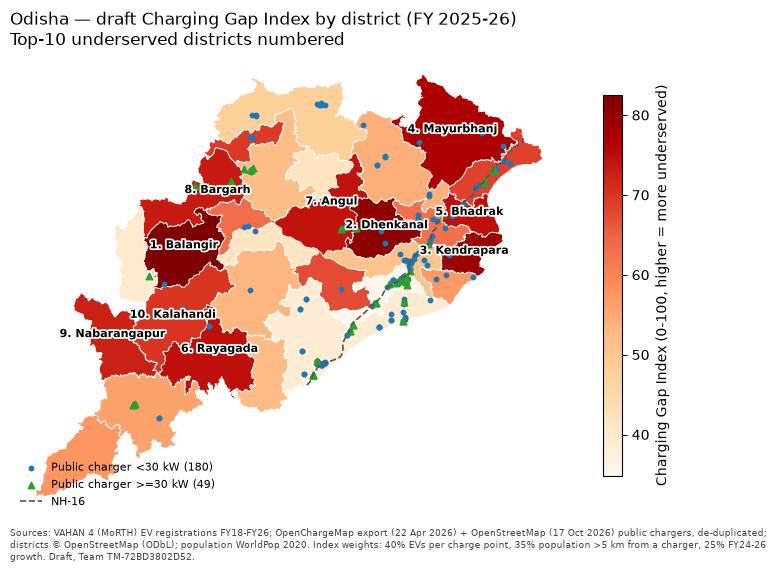

In [18]:
g = dist[dist.state == 'Odisha'].set_index('district').join(od[['gap_index', 'rank']])
co = chg[chg.state == 'Odisha']
fig, ax = plt.subplots(figsize=(9, 9))
g.plot(column='gap_index', cmap='OrRd', linewidth=.6, edgecolor='white', legend=True, ax=ax,
       legend_kwds=dict(label='Charging Gap Index (0-100, higher = more underserved)', shrink=.55))
co[co.kw_class == 'light'].plot(ax=ax, markersize=10, color='#1f77b4', marker='o', label=f'Public charger <30 kW ({(co.kw_class=="light").sum()})')
co[co.kw_class == 'DC'].plot(ax=ax, markersize=22, color='#2ca02c', marker='^', label=f'Public charger >=30 kW ({(co.kw_class=="DC").sum()})')
gpd.GeoSeries([center], crs=UTM).to_crs(4326).plot(ax=ax, color='#555', linewidth=1.2, linestyle='--', label='NH-16')
import matplotlib.patheffects as pe
for dname, r in g[g['rank'] <= 10].iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{int(r['rank'])}. {dname}", (p.x, p.y), ha='center', fontsize=8, weight='bold',
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])
ax.set_title('Odisha — draft Charging Gap Index by district (FY 2025-26)\nTop-10 underserved districts numbered', fontsize=12, loc='left')
ax.legend(loc='lower left', fontsize=8, frameon=False); ax.set_axis_off()
ax.text(0, -0.02, 'Sources: VAHAN 4 (MoRTH) EV registrations FY18-FY26; OpenChargeMap export (22 Apr 2026) + OpenStreetMap (17 Oct 2026) public chargers, '
         'de-duplicated; districts © OpenStreetMap (ODbL); population WorldPop 2020. Index weights: 40% EVs per charge point, '
         '35% population >5 km from a charger, 25% FY24-26 growth. Draft, Team TM-72BD3802D52.', fontsize=6.5, wrap=True, color='#444',
         transform=ax.transAxes, va='top')
fig.savefig(FIG/'odisha_gap_map.png', dpi=200, bbox_inches='tight'); plt.show()

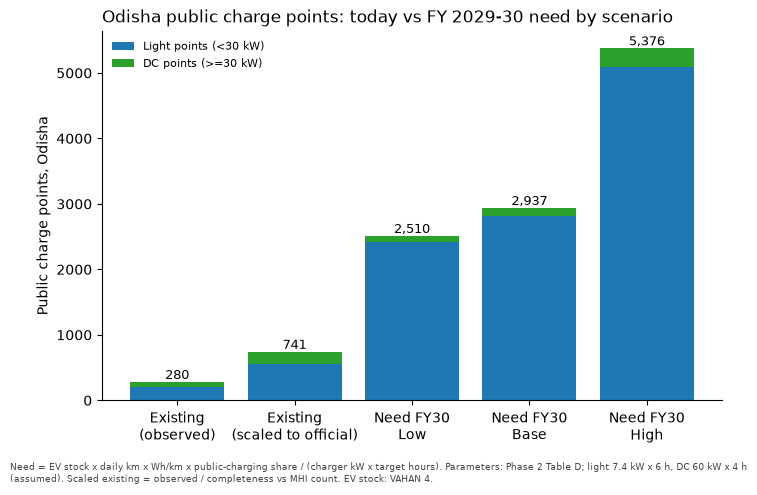

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.8))
labels = ['Existing\n(observed)', 'Existing\n(scaled to official)', 'Need FY30\nLow', 'Need FY30\nBase', 'Need FY30\nHigh']
light = [od.points_light.sum(), nsum.loc['exist_light', 'Base'], nsum.loc['req_light', 'Low'], nsum.loc['req_light', 'Base'], nsum.loc['req_light', 'High']]
dc = [od.points_dc.sum(), nsum.loc['exist_dc', 'Base'], nsum.loc['req_dc', 'Low'], nsum.loc['req_dc', 'Base'], nsum.loc['req_dc', 'High']]
ax.bar(labels, light, color='#1f77b4', label='Light points (<30 kW)')
ax.bar(labels, dc, bottom=light, color='#2ca02c', label='DC points (>=30 kW)')
for i, (l, d) in enumerate(zip(light, dc)): ax.text(i, l + d, f'{l + d:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Public charge points, Odisha'); ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Odisha public charge points: today vs FY 2029-30 need by scenario', loc='left', fontsize=12)
ax.legend(frameon=False, fontsize=8)
fig.text(.01, -.06, 'Need = EV stock x daily km x Wh/km x public-charging share / (charger kW x target hours). Parameters: Phase 2 Table D; '
         'light 7.4 kW x 6 h, DC 60 kW x 4 h (assumed). Scaled existing = observed / completeness vs MHI count. EV stock: VAHAN 4.', fontsize=6.5, wrap=True, color='#444')
fig.savefig(FIG/'ev_vs_chargers_chart.png', dpi=200, bbox_inches='tight'); plt.show()

In [20]:
cols = ['pop_2020', 'area_km2'] + SEG + ['ev_stock_in_scope', 'reg_cagr_fy24_fy26', 'sites', 'points_light', 'points_dc', 'points_total',
        'points_scaled', 'evs_per_point', 'evs_per_point_scaled', 'evs_per_lakh_pop', 'points_per_lakh_pop', 'pop_pct_beyond_5km',
        'ev_stock_fy30_base', 'req_light_base', 'req_dc_base', 'gap_light_base', 'gap_dc_base', 'gap_total_low', 'gap_total_base',
        'gap_total_high', 'gap_index', 'rank']
out = od[cols].sort_values('rank').round(2)
out['is_assumed_cols'] = 'points_scaled, evs_per_point_scaled, *_base/_low/_high, pop_pct_beyond_5km'
out.to_csv(TAB/'district_summary.csv')
nsum.to_csv(TAB/'charger_need_fy30_odisha.csv'); bt.round(1).to_csv(TAB/'forecast_backtest.csv'); S30.round(0).to_csv(TAB/'ev_stock_fy30_scenarios.csv')
sens.to_csv(TAB/'sensitivity_top10.csv'); corr.to_csv(TAB/'nh16_corridor_gaps.csv')

L_ = pd.DataFrame(LOG)
with open(TAB/'data_quality_log.md', 'w', encoding='utf-8') as f:
    f.write('# Data quality log — Phase 3 EDA (auto-generated by notebooks/01_eda_forecast.ipynb)\n\n')
    for sec, d in L_.groupby('section', sort=False):
        f.write(f'## {sec}\n\n| Item | Value | Note |\n|---|---|---|\n')
        for r in d.itertuples(): f.write(f'| {r.item} | {r.value} | {r.note} |\n')
        f.write('\n')
json.dump({'norm': norm, 'corridor': corr.reset_index().to_dict('records'), 'cmp': cmp.round(3).to_dict(),
           'need': nsum.to_dict(), 'S30': S30.round(0).to_dict(), 'backtest': bt.round(1).to_dict(),
           'top10': top10.index.tolist(), 'sens': sens.reset_index().to_dict('records'), 'summ': summ.reset_index().to_dict('records')},
          open(TAB/'_findings_numbers.json', 'w'), indent=1, default=str)
L_

,section,item,value,note
0,Assumptions,3W_AUTO attrition,2%/yr (no Phase2 value),is_assumed
1,Assumptions,4W DC share of public energy,60%,is_assumed
2,Assumptions,Representative light charger,7.4 kW,is_assumed
3,Assumptions,Representative DC charger,60 kW,is_assumed
4,Boundaries,name fix Mysuru District,Mysuru,OSM name -> common/LGD name
5,Boundaries,name fix Coorg,Kodagu,OSM name -> common/LGD name
6,Boundaries,name fix Shimoga,Shivamogga,OSM name -> common/LGD name
7,Boundaries,Odisha districts,30,"area 155,509 km2; WorldPop-2020 pop 46.5 M"
8,Boundaries,Karnataka districts,31,"area 191,830 km2; WorldPop-2020 pop 68.9 M"
9,VAHAN,Odisha FYs covered,FY2017-18 to FY2025-26,segment sums = TOTAL column for every FY


## 8. Round-1 pre-work: Gap Index weight sensitivity, observed vs scaled, registrations chart

In [21]:
from scipy.stats import spearmanr
def gi(Zm, w):
    w = pd.Series(w, dtype=float); w = w / w.sum()
    return sum(Zm[k] * w.get(k, 0) for k in ['pressure', 'coverage_gap', 'momentum'])
def zscale(Xm): return (Xm - Xm.min()) / (Xm.max() - Xm.min()) * 100
base = gi(Z, WEIGHTS); base_rank = base.rank(ascending=False); base_top = set(base.nlargest(10).index)
Zs = (Z - Z.mean()) / Z.std()
ev, evec = np.linalg.eigh(np.cov(Zs.T.values)); pc1 = np.abs(evec[:, -1]); pc1 = pc1 / pc1.sum()
Xcap = X.assign(momentum=X.momentum.clip(upper=X.momentum.quantile(.95)))
V = {'Base 40/35/25': (Z, WEIGHTS), 'Equal 33/33/33': (Z, dict(pressure=1, coverage_gap=1, momentum=1))}
for k1, k2 in [('pressure', 'coverage_gap'), ('coverage_gap', 'pressure'), ('pressure', 'momentum'),
               ('momentum', 'pressure'), ('coverage_gap', 'momentum'), ('momentum', 'coverage_gap')]:
    w = dict(WEIGHTS); w[k1] += .10; w[k2] -= .10
    V[f'+10 {k1} / -10 {k2}'] = (Z, w)
V[f'PCA PC1 ({pc1[0]:.2f}/{pc1[1]:.2f}/{pc1[2]:.2f})'] = (Z, dict(zip(['pressure', 'coverage_gap', 'momentum'], pc1)))
for k in WEIGHTS: V[f'Leave out {k}'] = (Z, {kk: vv for kk, vv in WEIGHTS.items() if kk != k})
V['Base, momentum capped at P95'] = (zscale(Xcap), WEIGHTS)
rows = []
for name, (Zm, w) in V.items():
    s = gi(Zm, w); r = s.rank(ascending=False)
    rows.append(dict(variant=name, spearman_rho=round(spearmanr(base, s).statistic, 3),
                     top10_overlap=len(set(s.nlargest(10).index) & base_top), max_rank_change=int((r - base_rank).abs().max())))
WS = pd.DataFrame(rows).set_index('variant'); WS.to_csv(TAB/'gap_index_weight_sensitivity.csv')
nonloo = WS[~WS.index.str.startswith('Leave out')].iloc[1:]
log('Gap Index sensitivity', 'Weight variants (excl. leave-one-out)', f"rho min {nonloo.spearman_rho.min():.2f}; top-10 overlap min {nonloo.top10_overlap.min()}/10", 'pass rule rho>=0.85 & overlap>=8')
WS

,spearman_rho,top10_overlap,max_rank_change
variant,,,
Base 40/35/25,1.000,10,0
Equal 33/33/33,0.975,10,4
+10 pressure / -10 coverage_gap,0.951,8,6
+10 coverage_gap / -10 pressure,0.977,10,4
+10 pressure / -10 momentum,0.965,8,5
+10 momentum / -10 pressure,0.962,10,6
+10 coverage_gap / -10 momentum,0.972,9,6
+10 momentum / -10 coverage_gap,0.960,8,5
PCA PC1 (0.46/0.40/0.13),0.968,9,6


In [22]:
X_sc = X.assign(pressure=np.log1p(od.ev_stock_in_scope / (od.points_scaled + 1)))
gi_obs, gi_sc = gi(Z, WEIGHTS), gi(zscale(X_sc), WEIGHTS)
OBS = pd.DataFrame({'GI_obs': gi_obs.round(1), 'rank_obs': gi_obs.rank(ascending=False).astype(int),
                    'GI_scaled': gi_sc.round(1), 'rank_scaled': gi_sc.rank(ascending=False).astype(int)})
OBS['rank_change'] = (OBS.rank_scaled - OBS.rank_obs).abs()
OBS.sort_values('rank_obs').to_csv(TAB/'gap_index_obs_vs_scaled.csv')
log('Gap Index sensitivity', 'GI_obs vs GI_scaled', f"max rank change {OBS.rank_change.max()}; districts >=5: {list(OBS[OBS.rank_change >= 5].index)}",
    'uniform completeness scaling; non-uniform missingness not testable with current data')
OBS.sort_values('rank_obs')

,GI_obs,rank_obs,GI_scaled,rank_scaled,rank_change
district,,,,,
Balangir,82.5,1,82.5,1,0
Dhenkanal,80.6,2,78.7,3,1
Kendrapara,79.2,3,79.2,2,1
Mayurbhanj,77.2,4,73.8,4,0
Bhadrak,74.7,5,70.9,6,1
Rayagada,74.5,6,72.7,5,1
Angul,74.3,7,70.4,8,1
Bargarh,73.1,8,69.9,9,1
Nabarangapur,72.5,9,70.7,7,2


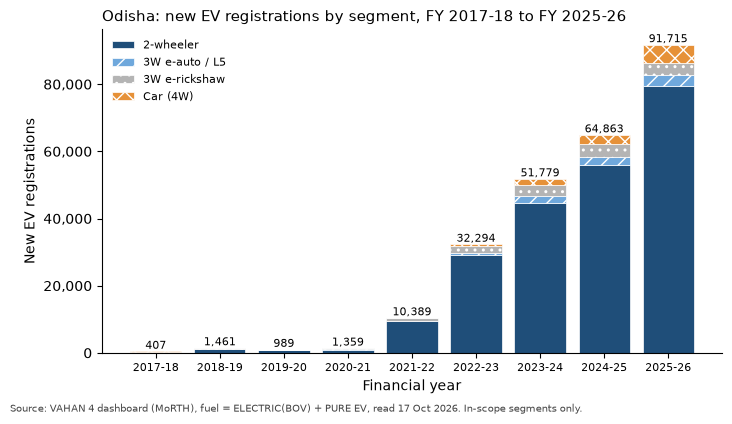

In [23]:
R = reg_od[reg_od.segment.isin(SEG)].pivot_table(index='fy_start', columns='segment', values='registrations', aggfunc='sum').fillna(0)[SEG]
lab = {'2W': '2-wheeler', '3W_AUTO': '3W e-auto / L5', '3W_ERICK': '3W e-rickshaw', '4W': 'Car (4W)'}
col = {'2W': '#1f4e79', '3W_AUTO': '#6fa8dc', '3W_ERICK': '#b4b4b4', '4W': '#e69138'}
hat = {'2W': '', '3W_AUTO': '//', '3W_ERICK': '..', '4W': 'xx'}
fig, ax = plt.subplots(figsize=(8, 4.2)); bottom = np.zeros(len(R))
xl = [f'{y}-{str(y+1)[2:]}' for y in R.index]
for s in SEG:
    ax.bar(xl, R[s], bottom=bottom, color=col[s], hatch=hat[s], edgecolor='white', linewidth=.5, label=lab[s]); bottom += R[s].values
for i, v in enumerate(bottom): ax.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_ylabel('New EV registrations'); ax.set_xlabel('Financial year'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{v:,.0f}')); ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Odisha: new EV registrations by segment, FY 2017-18 to FY 2025-26', loc='left', fontsize=11)
ax.legend(frameon=False, fontsize=8, loc='upper left'); plt.xticks(fontsize=8)
fig.text(.01, -.03, 'Source: VAHAN 4 dashboard (MoRTH), fuel = ELECTRIC(BOV) + PURE EV, read 17 Oct 2026. In-scope segments only.', fontsize=7, color='#444')
fig.savefig(FIG/'odisha_ev_registrations_fy18_fy26.png', dpi=220, bbox_inches='tight'); plt.show()